In [2]:
import nltk
import torch
import matplotlib.pyplot as plt 
from nltk import word_tokenize, pos_tag, ne_chunk 
from transformers import AutoTokenizer, AutoModelForTokenClassification, AutoModel, pipeline 

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\nltk\metrics\association.py:26: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import fisher_exact


In [3]:
nltk.download("punkt")
nltk.download("averaged_perceptron_tagger") 
nltk.download("maxent_ne_chunker")
nltk.download("words") 

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package maxent_ne_chunker is already up-to-date!
[nltk_data] Downloading package words to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!


True

In [5]:
def nltk_ner(text): 
    t = pos_tag(word_tokenize(text)) 
    tree = ne_chunk(t) 
    return [(n.label(), " ".join(w for w,_ in n.leaves())) 
            for n in tree if hasattr(n, "label")]

In [7]:
name = "dslim/bert-base-NER" 
tok = AutoTokenizer.from_pretrained(name) 
ner_model = AutoModelForTokenClassification.from_pretrained(name) 
bert_ner = pipeline("ner", model=ner_model, tokenizer=tok, 
                    aggregation_strategy="simple") 
text = "Barack Obama visited Microso headquarters in Washington." 
 
print("\n=== NLTK vs BERT NER ===") 
print("NLTK :", nltk_ner(text)) 
bert_out = bert_ner(text) 
print("BERT :", [(x['word'], x['entity_group']) for x in bert_out]) 

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DELL\.cache\huggingface\hub\models--dslim--bert-base-NER. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Some weights of the model checkpoint at dslim/bert-base-NER were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu



=== NLTK vs BERT NER ===
NLTK : [('PERSON', 'Barack'), ('PERSON', 'Obama'), ('PERSON', 'Microso'), ('GPE', 'Washington')]
BERT : [('Barack Obama', 'PER'), ('Microso', 'ORG'), ('Washington', 'LOC')]


In [8]:
att_model = AutoModel.from_pretrained(name, output_attentions=True) 
inputs = tok(text, return_tensors="pt") 
outputs = att_model(**inputs) 

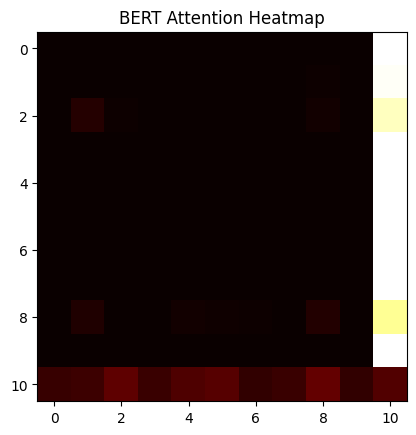

In [11]:
a = outputs.attentions[-1][0][0].detach().numpy()   # last layer, head 0 
 
plt.imshow(a , cmap="hot") 
plt.title("BERT Attention Heatmap") 
plt.show() 